# 03 · Possession value

What a player's passes and carries are worth. The profiles count actions (progressive passes,
passes into the box); possession value weighs each one by how much closer it takes the ball to a
goal, so that a pass into the six-yard box counts for more than many sideways passes in midfield.

1. **The xT map.** What having the ball in each zone of the pitch is worth: whether the map
   predicts what happened in matches it was not fitted on, which actions it should count, how
   fine its zones should be, and whether one map fits both wings and all four leagues.

**Actions:** open play in the four leagues of the scouting pool (Premier League, La Liga, Serie A
and Ligue 1, 2015/16). Carried over from `01_data_exploration.ipynb`: event locations share one
scale across leagues (section 6), and xG is StatsBomb's as published (section 5).

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events). Only aggregated
results are shown, as StatsBomb's licence requires. Tables are built by `make model`; see
`docs/DATA_DICTIONARY.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LogNorm
from mplsoccer import Pitch

from football_scouting.analysis.metrics import ON_BALL
from football_scouting.analysis.xt import (
    LENGTH,
    POOL,
    WIDTH,
    chain_outcomes,
    fit,
    load_actions,
    move_credit,
    value_at,
    zones,
)
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import GREY, OKABE_ITO, credit, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()
STATSBOMB = "Data: StatsBomb Open Data (2015/16)"
NX, NY = cfg.xt.nx, cfg.xt.ny

actions = load_actions(con, losses=True).merge(
    chain_outcomes(con), on=["match_id", "event_index", "team_id"], how="left", validate="1:1"
)
league = con.sql(
    "SELECT match_id, c.competition_name AS league FROM matches m "
    "JOIN competitions c USING (competition_id, season_id) WHERE m.scouting_pool"
).df()
actions = actions.merge(league, on="match_id", validate="m:1")
LEAGUES = [c.name for c in cfg.statsbomb.competitions if c.scouting_pool]
print(
    f"{actions.match_id.nunique():,} matches, {len(actions):,} open-play actions: "
    + ", ".join(
        f"{n:,} {dict(move='moves', loss='losses', shot='shots')[k]}"
        for k, n in actions.kind.value_counts().items()
    )
    + "."
)

1,517 matches, 2,577,884 open-play actions: 2,434,360 moves, 107,792 losses, 35,732 shots.


## 1. The xT map

Expected threat (xT; Karun Singh, 2018) cuts the pitch into zones. From each zone a team shoots,
moves the ball on (a pass or a carry) or gives it away. The xT of a zone is the xG of the shots
taken there plus the xT of the zones its successful moves reach, each weighted by how often it
happens; a failed move ends the chain with nothing. A move is then worth the xT it gains,
xT(end) − xT(start) (`analysis.xt`).

Only open play counts. A set piece's value comes from the routine, not from the zone it starts
in, so corners, free kicks, throw-ins, goal kicks and kick-offs, and shots straight from them,
are left out; what follows them in open play stays. Dribbles move the ball through the carry
recorded with them.

Every map is checked against what happened in matches it was not fitted on. Each action's
outcome is the xG of the open-play shot its team's chain went on to take (0 if none), where a
chain ends at the opponent's next action on the ball, a set piece or the end of the half
(`chain_outcomes`). A map fitted on half of the matches predicts the outcomes of the other half:
**skill** is the share of a flat guess's squared error (the training half's mean) that the map
removes, and **level** the mean predicted over the mean observed (1 when the map is right on
average). Outcomes are mostly 0 and now and then a large xG, so skill is small for any map; what
counts is how it compares between maps.

### 1.1 The actions

The actions the map is built from, and what comes after them.

In [2]:
on_ball = ", ".join(f"'{t}'" for t in [*ON_BALL, "Goal Keeper"] if t != "Ball Receipt*")
# The next action on the ball after each event: the same team's, in open play?
kept = con.sql(f"""
    SELECT e.match_id, e.event_index,
           lead(e.team_id) OVER w = e.team_id
           AND NOT coalesce(lead(p.pass_type NOT IN ('Recovery', 'Interception')) OVER w, FALSE)
           AS kept
    FROM events e LEFT JOIN passes p USING (event_id, match_id)
    WHERE e.{POOL} AND e.type IN ({on_ball})
    WINDOW w AS (PARTITION BY e.match_id ORDER BY e.event_index)
""").df()
acts = actions.merge(kept, on=["match_id", "event_index"], how="left", validate="1:1")
acts["row"] = np.select(
    [
        (acts.type == "Pass") & acts.success.fillna(False),
        acts.type == "Pass",
        acts.type == "Carry",
        acts.type == "Shot",
    ],
    ["Passes, completed", "Passes, failed", "Carries", "Shots"],
    default=acts.type.map(
        {"Dispossessed": "Dispossessed", "Miscontrol": "Miscontrols", "Dribble": "Failed dribbles"}
    ),
)
ROWS = [
    "Passes, completed", "Passes, failed", "Carries", "Shots", "Dispossessed", "Miscontrols",
    "Failed dribbles",
]  # fmt: skip
table = acts.groupby("row").agg(
    actions=("kind", "size"),
    kept=("kept", "mean"),
    outcome=("outcome", "mean"),
    own_half=("x", lambda x: (x < LENGTH / 2).mean()),
)
table = table.loc[ROWS].rename_axis(index=None)
table.columns = ["Actions", "Same team next", "Chain's xG", "In own half"]
display(
    table.style.format(
        {
            "Actions": "{:,}",
            "Same team next": "{:.1%}",
            "Chain's xG": "{:.4f}",
            "In own half": "{:.0%}",
        }
    ).set_caption(
        "Open-play actions: how many, how often the next action on the ball is the same team's in "
        "open play, the mean xG of the shot their chain leads to, the share in the own half"
    )
)

,Actions,Same team next,Chain's xG,In own half
"Passes, completed","1,021,195",99.9%,0.0092,54%
"Passes, failed","295,969",0.4%,0.0000,48%
Carries,"1,117,196",97.5%,0.0083,50%
Shots,"35,732",0.9%,0.0941,0%
Dispossessed,"39,944",19.9%,0.0016,28%
Miscontrols,"44,606",6.6%,0.0009,25%
Failed dribbles,"23,242",16.9%,0.0014,24%


- A failed pass gives the ball away: the opponent, or a set piece, comes next almost every time
  (StatsBomb marks a pass incomplete when no teammate receives it). After a completed pass or a
  carry the team almost always plays on.
- The textbook model counts only shots and moves, but 107,792 other actions also give the ball
  away: being dispossessed, a miscontrol, a failed dribble. The opponent or a set piece comes
  next after 80% to 93% of them, and three quarters happen in the opponent's half, where chains
  are worth the most.
- A completed pass leads on average to 0.009 xG; a shot's chain ends with the shot (0.094).

### 1.2 The textbook map, and what it leaves out

The textbook map (16 × 12 zones of 7.5 × 6.7 yards, shots and moves only) against the same
model with losses counted as actions that end the chain, like a failed move, and against the
plainest estimate: each zone's mean outcome in the training half (zone average).

In [3]:
GRIDS = [(12, 8), (16, 12), (24, 16), (30, 20), (48, 32), (60, 40)]
MODELS = ["Shots and moves", "With losses", "Zone average"]
DRAWS = 20
outcome = actions.outcome.to_numpy()
is_loss = (actions.kind == "loss").to_numpy()
moved = ((actions.kind == "move") & actions.success.fillna(False)).to_numpy()
matches = np.sort(actions.match_id.unique())
rng = np.random.default_rng(2015)
held_out, calibration = [], []
for draw in range(DRAWS):
    train = actions.match_id.isin(rng.permutation(matches)[: len(matches) // 2]).to_numpy()
    test = ~train
    flat = np.mean((outcome[test] - outcome[train].mean()) ** 2)
    for nx, ny in GRIDS:
        z = zones(actions.x, actions.y, nx, ny)
        n_zone = np.bincount(z[train], minlength=nx * ny)
        maps = {
            "Shots and moves": fit(actions[train & ~is_loss], nx, ny).ravel(),
            "With losses": fit(actions[train], nx, ny).ravel(),
            "Zone average": np.bincount(z[train], weights=outcome[train], minlength=nx * ny)
            / np.maximum(n_zone, 1),
        }
        # The same map from the other half: how much the credit of each move depends on the half.
        other = fit(actions[test], nx, ny)
        c1 = move_credit(maps["With losses"].reshape(ny, nx), actions)[moved]
        c2 = move_credit(other, actions)[moved]
        for model, m in maps.items():
            pred = m[z[test]]
            held_out.append({
                "draw": draw, "grid": f"{nx} x {ny}", "model": model,
                "skill": 1 - np.mean((outcome[test] - pred) ** 2) / flat,
                "level": pred.mean() / outcome[test].mean(),
                "fewest": n_zone.min(),
                "credit_r": np.corrcoef(c1, c2)[0, 1] if model == "With losses" else np.nan,
            })  # fmt: skip
            if (nx, ny) in [(16, 12), (NX, NY)] and model != "Zone average":
                bins = pd.qcut(pd.Series(pred).rank(method="first"), 20, labels=False)
                calibration.append(
                    pd.DataFrame({"pred": pred, "obs": outcome[test], "bin": bins})
                    .groupby("bin").mean().assign(draw=draw, grid=f"{nx} x {ny}", model=model)
                )  # fmt: skip
held_out = pd.DataFrame(held_out)
calibration = pd.concat(calibration).groupby(["grid", "model", "bin"])[["pred", "obs"]].mean()

singh = fit(actions[~is_loss], 16, 12)
with_losses = fit(actions, 16, 12)
summary = held_out[held_out.grid == "16 x 12"].groupby("model")[["skill", "level"]].mean()
display(
    summary.loc[MODELS]
    .rename_axis(index=None)
    .style.format({"skill": "{:.4f}", "level": "{:.2f}"})
    .set_caption(
        f"16 x 12 zones, fitted on half of the matches and checked on the other half "
        f"({DRAWS} draws): skill (share of a flat guess's squared error removed) and level "
        "(mean predicted over mean observed)"
    )
)
c_singh = move_credit(singh, actions)[moved]
c_losses = move_credit(with_losses, actions)[moved]
ratio = with_losses / singh
print(
    "Moves' credit, textbook against with losses: "
    f"Pearson {np.corrcoef(c_singh, c_losses)[0, 1]:.3f}, "
    f"Spearman {pd.Series(c_singh).corr(pd.Series(c_losses), method='spearman'):.3f}. "
    f"With losses, xT is {ratio[:, : 16 // 2].mean():.2f} times the textbook's in the own half "
    f"and {ratio[4:8, -1].mean():.2f} times in front of goal."
)

,skill,level
Shots and moves,0.0809,1.46
With losses,0.0915,0.87
Zone average,0.0926,1.01


Moves' credit, textbook against with losses: Pearson 0.996, Spearman 0.990. With losses, xT is 0.48 times the textbook's in the own half and 0.89 times in front of goal.


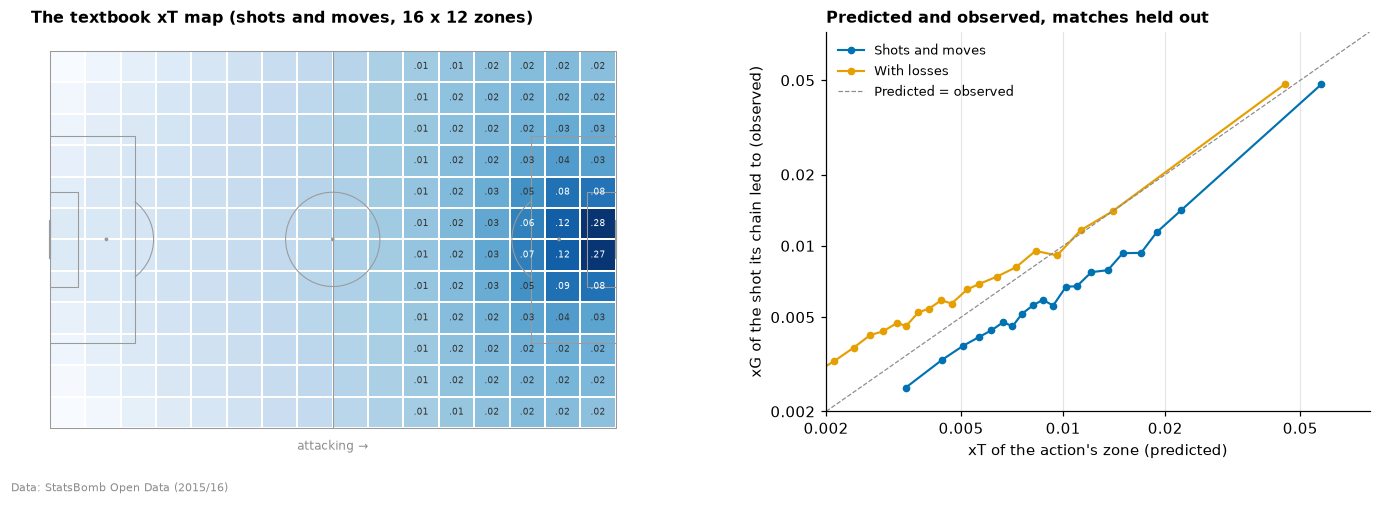

In [4]:
pitch = Pitch(pitch_type="statsbomb", line_color="#9A9A9A", linewidth=0.7, line_zorder=2)
fig = plt.figure(figsize=(13, 4.6))
ax_map = fig.add_axes([0.0, 0.05, 0.47, 0.82])
ax_cal = fig.add_axes([0.58, 0.12, 0.38, 0.75])
stat = pitch.bin_statistic(actions.x, actions.y, statistic="count", bins=(16, 12))
stat["statistic"] = singh
pitch.draw(ax=ax_map)
pitch.heatmap(stat, ax=ax_map, cmap="Blues", norm=LogNorm(0.002, 0.3), edgecolors="white", lw=0.3)
for (row, col), v in np.ndenumerate(singh):
    if col >= 10:
        ax_map.text(
            stat["cx"][row, col], stat["cy"][row, col], f"{v:.2f}".lstrip("0"), ha="center",
            va="center", fontsize=6, color="white" if v > 0.05 else "#333333",
        )  # fmt: skip
ax_map.set_title("The textbook xT map (shots and moves, 16 x 12 zones)", fontsize=10.5)
ax_map.text(60, 82.5, "attacking →", ha="center", va="top", fontsize=8, color=GREY)
for model, color in zip(["Shots and moves", "With losses"], OKABE_ITO, strict=False):
    c = calibration.loc[("16 x 12", model)]
    ax_cal.plot(c.pred, c.obs, "o-", color=color, ms=4, lw=1.4, label=model)
lims = [0.002, 0.08]
ax_cal.plot(lims, lims, color=GREY, lw=0.8, ls="--", label="Predicted = observed")
ax_cal.set(
    xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="xT of the action's zone (predicted)",
    ylabel="xG of the shot its chain led to (observed)",
)  # fmt: skip
ticks = [0.002, 0.005, 0.01, 0.02, 0.05]
ax_cal.set_xticks(ticks, labels=[f"{t:g}" for t in ticks])
ax_cal.set_yticks(ticks, labels=[f"{t:g}" for t in ticks])
ax_cal.minorticks_off()
ax_cal.set_title("Predicted and observed, matches held out", fontsize=10.5)
ax_cal.grid(axis="both")
ax_cal.legend(loc="upper left", fontsize=8.5)
credit(fig, STATSBOMB)
plt.show()

- **The textbook map overstates what happens by 46%.** Its chains run on through the
  dispossessions, miscontrols and failed dribbles it does not see. Counting them turns the map
  13% low, partly because a loss does not always end the chain (one dispossession in five), and
  lifts its held-out skill from 0.081 to 0.092, level with the zone average (0.093). In the
  calibration plot the textbook map sits below the line everywhere; with losses the final third
  is on it and the deep zones a little above.
- Losses keep the map's shape and change the weight of the build-up. xT in the own half halves
  (0.48 times the textbook's) while in front of goal it barely moves (0.89 times). The order of
  moves by credit hardly changes (Spearman 0.990), but a move in the own half now earns about
  half as much as before against one near the box.

### 1.3 How fine the zones should be

Finer zones tell a shot from the penalty spot from one at the edge of the six-yard box, but each
zone has fewer actions to learn from. Six grids, from 10-yard to 2-yard zones, on the same draws:
held-out skill, the gain of each grid over the coarser one before it (paired by draw), and how
much a move's credit depends on which half of the matches the map was fitted on (correlation of
every successful move's credit between the maps of two halves).

In [5]:
size = pd.Series({f"{nx} x {ny}": f"{LENGTH / nx:.1f} x {WIDTH / ny:.1f}" for nx, ny in GRIDS})
by_grid = held_out.pivot_table(index="grid", columns="model", values="skill", sort=False)
gain = (
    held_out[held_out.model == "With losses"].pivot(index="draw", columns="grid", values="skill")
    [size.index].diff(axis=1)
)  # fmt: skip
low, high = gain.quantile(0.025), gain.quantile(0.975)
losses = held_out[held_out.model == "With losses"].groupby("grid", sort=False)
grids = pd.DataFrame({
    "Zone (yards)": size,
    "Fewest actions in a zone": losses.fewest.min(),
    "Skill: with losses": by_grid["With losses"],
    "Skill: shots and moves": by_grid["Shots and moves"],
    "Skill: zone average": by_grid["Zone average"],
    "Gain on the coarser grid": gain.mean(),
    "95% range": (low.map("{:+.4f}".format) + " to " + high.map("{:+.4f}".format)).where(
        low.notna(), ""
    ),
    "Credit, half against half": losses.credit_r.mean(),
}).loc[size.index].rename_axis(index=None)  # fmt: skip
display(
    grids.style.format(
        {c: "{:.4f}" for c in grids.columns if c.startswith(("Skill", "Gain", "Credit"))}
        | {"Fewest actions in a zone": "{:,}"},
        na_rep="",
    ).set_caption(
        f"Held-out skill by grid ({DRAWS} draws of half the matches); gain of each grid on the "
        "one above it, the same draws; correlation of moves' credit between maps of two halves"
    )
)

,Zone (yards),Fewest actions in a zone,Skill: with losses,Skill: shots and moves,Skill: zone average,Gain on the coarser grid,95% range,"Credit, half against half"
12 x 8,10.0 x 10.0,"2,212",0.0800,0.0686,0.0810,,,0.9992
16 x 12,7.5 x 6.7,742,0.0915,0.0809,0.0926,0.0115,+0.0109 to +0.0123,0.9986
24 x 16,5.0 x 5.0,242,0.0963,0.0854,0.0973,0.0048,+0.0029 to +0.0059,0.9968
30 x 20,4.0 x 4.0,102,0.0984,0.0880,0.0993,0.0021,+0.0009 to +0.0033,0.9951
48 x 32,2.5 x 2.5,13,0.1017,0.0915,0.1020,0.0034,+0.0022 to +0.0043,0.9882
60 x 40,2.0 x 2.0,2,0.1022,0.0917,0.1017,0.0004,-0.0004 to +0.0013,0.9812


- Skill rises with every finer grid down to zones of 2.5 yards (48 × 32: 0.102, against 0.092 at
  the textbook's 16 × 12). At 2 yards (60 × 40) the gain stops (+0.0004, with a range from
  −0.0004 to +0.0013).
- A move's credit barely depends on the matches: 0.988 between the maps of two halves at
  2.5 yards, 0.999 at 10 yards.
- Counting losses is better at every grid. The chain keeps up with the zone average down to
  2.5 yards and passes it at 2 yards, where a zone can hold as few as two actions in half a
  season.
- **The map uses 48 × 32 zones of 2.5 × 2.5 yards** (`xt` in `config/pipeline.yaml`).

### 1.4 One map for both wings and all four leagues

One map for the whole pool assumes that a zone is worth the same on either wing and in every
league, and that a shot is best valued by its xG. Three checks, at 48 × 32 zones:

- **Left and right:** each zone's xT against its mirror image across the pitch, next to the
  difference between the maps of two halves of the matches (action-weighted mean absolute
  difference over the mean xT).
- **Leagues:** each league's own map against the pooled one, next to 50 random sets of 380
  matches: level (the mean xT of the league's actions under its own map, over the pooled map's)
  and the correlation of its moves' credit.
- **Goals:** shots valued by whether they were scored instead of their xG.

In [6]:
xt_map = fit(actions, NX, NY)
weight = np.bincount(zones(actions.x, actions.y, NX, NY), minlength=NX * NY).reshape(NY, NX)


def gap(a, b):
    """Action-weighted mean absolute difference between two maps, over the map's mean."""
    return np.sum(weight * np.abs(a - b)) / np.sum(weight * xt_map)


def credit_r(a, b, rows):
    ca, cb = move_credit(a, rows), move_credit(b, rows)
    ok = ~np.isnan(ca)
    return np.corrcoef(ca[ok], cb[ok])[0, 1]


def level(m, rows):
    """Mean xT of the rows' zones under map m, over the pooled map's."""
    return value_at(m, rows.x, rows.y).mean() / value_at(xt_map, rows.x, rows.y).mean()


rng = np.random.default_rng(16)
halves = []
for _ in range(DRAWS):
    train = actions.match_id.isin(rng.permutation(matches)[: len(matches) // 2])
    halves.append((fit(actions[train], NX, NY), fit(actions[~train], NX, NY)))
print(
    "Left against right (each zone against its mirror image across the pitch): "
    f"{gap(xt_map, xt_map[::-1]):.3f}; two halves of the matches: "
    f"{np.mean([gap(a, b) for a, b in halves]):.3f} (mean of {DRAWS} draws)."
)

# Each league's own map against the pooled one, and random sets of as many matches.
rows = []
for name in LEAGUES:
    own = actions[actions.league == name]
    m = fit(own, NX, NY)
    rows.append({"set": name, "level": level(m, own), "credit_r": credit_r(m, xt_map, own)})
null = []
for _ in range(50):
    pick = actions[actions.match_id.isin(rng.choice(matches, 380, replace=False))]
    m = fit(pick, NX, NY)
    null.append({"level": level(m, pick), "credit_r": credit_r(m, xt_map, pick)})
null = pd.DataFrame(null)
leagues = pd.DataFrame(rows).set_index("set").rename_axis(index=None)
leagues.columns = ["Level", "Credit against the pooled map"]
leagues.loc["380 random matches (95% range)"] = [
    f"{null.level.quantile(0.025):.3f} to {null.level.quantile(0.975):.3f}",
    f"{null.credit_r.quantile(0.025):.4f} to {null.credit_r.quantile(0.975):.4f}",
]
display(
    leagues.style.format(lambda v: v if isinstance(v, str) else f"{v:.4f}").set_caption(
        "Each league's own map against the pooled map: level (mean xT of the league's actions, "
        "over the pooled map's) and correlation of moves' credit; 50 random sets of 380 matches"
    )
)

goals_map = fit(actions, NX, NY, shot_value="goal")
goal_halves = []
rng = np.random.default_rng(16)
for _ in range(DRAWS):
    train = actions.match_id.isin(rng.permutation(matches)[: len(matches) // 2])
    goal_halves.append(
        (
            fit(actions[train], NX, NY, shot_value="goal"),
            fit(actions[~train], NX, NY, shot_value="goal"),
        )
    )
shot_values = pd.DataFrame(
    {
        "Level against the xG map": [1.0, level(goals_map, actions)],
        "Credit against the xG map": [1.0, credit_r(goals_map, xt_map, actions)],
        "Credit, half against half": [
            np.mean([credit_r(a, b, actions) for a, b in halves]),
            np.mean([credit_r(a, b, actions) for a, b in goal_halves]),
        ],
    },
    index=["Shots valued by xG", "Shots valued by goals"],
)
display(
    shot_values.style.format("{:.3f}").set_caption(
        f"Shots valued by their xG or by goals ({NX} x {NY} zones; halves: mean of {DRAWS} draws)"
    )
)

Left against right (each zone against its mirror image across the pitch): 0.040; two halves of the matches: 0.058 (mean of 20 draws).


,Level,Credit against the pooled map
Premier League,0.9858,0.9906
La Liga,1.0587,0.9905
Serie A,1.0181,0.9890
Ligue 1,0.9409,0.9910
380 random matches (95% range),0.972 to 1.032,0.9891 to 0.9933


,Level against the xG map,Credit against the xG map,"Credit, half against half"
Shots valued by xG,1.000,1.000,0.988
Shots valued by goals,1.020,0.990,0.948


- **The two wings are the same within noise:** a zone differs from its mirror image by 4.0% of the
  mean xT, less than the maps of two halves of the matches differ (5.8%).
- **The leagues share the map's shape:** their moves' credit agrees with the pooled map's as
  closely as random sets of matches do (0.989 to 0.991; Serie A at the lower edge of the random
  range). The level differs beyond chance in two leagues: from the same zones, La Liga's chains
  reach 5.9% more xG and Ligue 1's 5.9% less (random sets: −2.8% to +3.2%). That gap comes with
  the players who carry the chains on, not with the zone; a league's own map would credit a
  pass in La Liga with the quality of the forwards who receive it. **One pooled map** values
  every move on one scale.
- **Goals** give the same map, 2% higher (non-penalty xG runs below goals, EDA section 5), with
  credits that agree at 0.990, but noisier between halves (0.948 against 0.988). **Shots are
  valued by their xG.**

### 1.5 The map

The map as used from here on: 48 × 32 zones, losses counted, shots valued by their xG, the four
leagues together.

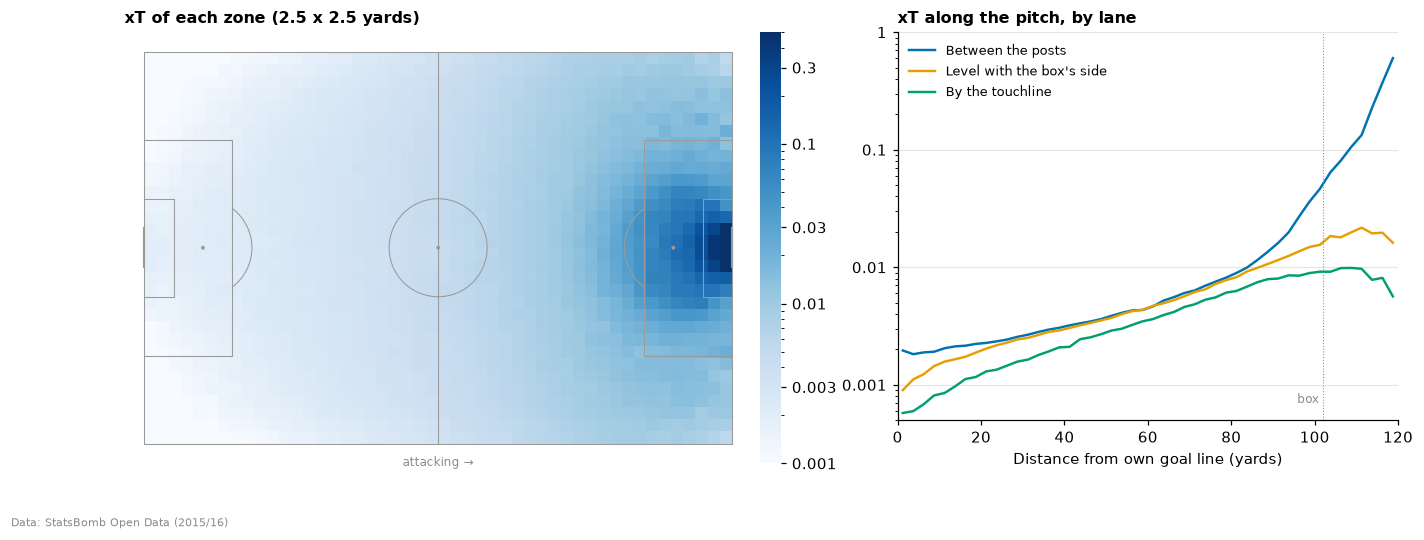

,xT
"Own penalty area (12, 40)",0.002
"Halfway line, centre (60, 40)",0.004
"30 yards out, centre (90, 40)",0.016
"Edge of the box, centre (102, 40)",0.046
"Wide, level with the box (108, 10)",0.015
"Penalty spot (108, 40)",0.118
"Six-yard box, centre (115, 40)",0.434


In [7]:
fig = plt.figure(figsize=(13, 4.9))
ax_map = fig.add_axes([0.0, 0.08, 0.55, 0.8])
ax_line = fig.add_axes([0.63, 0.16, 0.35, 0.72])
stat = pitch.bin_statistic(actions.x, actions.y, statistic="count", bins=(NX, NY))
stat["statistic"] = xt_map
pitch.draw(ax=ax_map)
mesh = pitch.heatmap(stat, ax=ax_map, cmap="Blues", norm=LogNorm(0.001, 0.5), edgecolors="none")
bar = fig.colorbar(mesh, ax=ax_map, fraction=0.03, pad=0.01)
bar.set_ticks([0.001, 0.003, 0.01, 0.03, 0.1, 0.3])
bar.set_ticklabels(["0.001", "0.003", "0.01", "0.03", "0.1", "0.3"])
bar.outline.set_visible(False)
ax_map.set_title(f"xT of each zone ({LENGTH / NX:.1f} x {WIDTH / NY:.1f} yards)", fontsize=10.5)
ax_map.text(60, 82.5, "attacking →", ha="center", va="top", fontsize=8, color=GREY)
x = stat["cx"][0]
lanes = {
    "Between the posts": (36, 44),
    "Level with the box's side": (18, 22),
    "By the touchline": (0, 5),
}
for (name, (lo, hi)), color in zip(lanes.items(), OKABE_ITO, strict=False):
    rows_in = (stat["cy"][:, 0] > lo) & (stat["cy"][:, 0] < hi)
    ax_line.plot(x, xt_map[rows_in].mean(axis=0), color=color, lw=1.6, label=name)
ax_line.set(
    yscale="log", xlim=(0, 120), ylim=(0.0005, 1), xlabel="Distance from own goal line (yards)",
)  # fmt: skip
ax_line.set_yticks([0.001, 0.01, 0.1, 1], labels=["0.001", "0.01", "0.1", "1"])
ax_line.axvline(102, color=GREY, lw=0.7, ls=":")
ax_line.text(101, 0.0007, "box", ha="right", fontsize=8, color=GREY)
ax_line.set_title("xT along the pitch, by lane", fontsize=10.5)
ax_line.legend(loc="upper left", fontsize=8.5)
credit(fig, STATSBOMB)
plt.show()

spots = {
    "Own penalty area (12, 40)": (12, 40),
    "Halfway line, centre (60, 40)": (60, 40),
    "30 yards out, centre (90, 40)": (90, 40),
    "Edge of the box, centre (102, 40)": (102, 40),
    "Wide, level with the box (108, 10)": (108, 10),
    "Penalty spot (108, 40)": (108, 40),
    "Six-yard box, centre (115, 40)": (115, 40),
}
xs, ys = np.array(list(spots.values())).T
display(
    pd.DataFrame({"xT": value_at(xt_map, xs, ys)}, index=list(spots))
    .style.format("{:.3f}")
    .set_caption("xT at a few spots (StatsBomb coordinates, yards)")
)

### What section 1 shows

- **The map.** Having the ball is worth little until the last third of the pitch: 0.002 in the own
  box, 0.004 at the centre spot, 0.016 thirty yards out. Then it climbs: 0.046 at the edge of the
  box, 0.118 on the penalty spot, 0.43 in the middle of the six-yard box. Wide areas stay low
  (0.015 by the touchline, level with the box). A move is worth the xT it gains.
- **Losses count.** The textbook model, which sees only shots and moves, overstates what
  possessions lead to by 46%. Counting dispossessions, miscontrols and failed dribbles as the
  end of a chain brings it within 13% and lifts its held-out skill to that of the zone average.
  It halves the worth of the build-up against the final third, but hardly changes the order of
  moves.
- **Zones of 2.5 yards** predict held-out matches best (finer zones add nothing), and a move's
  credit is nearly the same from either half of the matches (0.988).
- **One map** fits both wings and all four leagues. La Liga's chains reach 6% more xG from the
  same zones and Ligue 1's 6% less, a gap that belongs to the players rather than the zones.
  Shots are valued by their xG: goals give the same map with more noise.
- **Next:** each player's xT per 90 from passes and carries, how reliable it is, how much it
  depends on possession and the team, what it adds to the profiles, and how failed moves count
  against a player.